In [1]:
#import
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files
uploaded = files.upload() # cari dan masukan data "DATA SET 015 029 (1).xlsx"

In [3]:
# 1. INPUT & PRE-PROCESSING DATA
file_path = "DATA SET 015 029 (1).xlsx"
df_y = pd.read_excel(file_path, sheet_name='Y')
df_x1 = pd.read_excel(file_path, sheet_name='X1')
df_x2 = pd.read_excel(file_path, sheet_name='X2')
df_x3 = pd.read_excel(file_path, sheet_name='X3')
df_x4 = pd.read_excel(file_path, sheet_name='X4')

In [4]:
# Fungsi standarisasi nama provinsi
def clean_prov(s):
    if not isinstance(s, str): return s
    s = s.strip().upper()
    s = s.replace('KEP. ', 'KEPULAUAN ')
    s = s.replace('D I YOGYAKARTA', 'DI YOGYAKARTA')
    return s

# Ekstraksi kolom relevan dan pembersihan awal
df_y_clean = df_y.iloc[:, [0, 1]].dropna().rename(columns={df_y.columns[0]: 'Provinsi', df_y.columns[1]: 'Y_IPM'})
df_x1_clean = df_x1.iloc[1:, [0, 3]].dropna().rename(columns={df_x1.columns[0]: 'Provinsi', df_x1.columns[3]: 'X1_AHH'})
df_x2_clean = df_x2.iloc[2:, [0, 1]].dropna(subset=[df_x2.columns[0]]).rename(columns={df_x2.columns[0]: 'Provinsi', df_x2.columns[1]: 'X2_HLS'})
df_x3_clean = df_x3.iloc[2:, [0, 1]].dropna(subset=[df_x3.columns[0]]).rename(columns={df_x3.columns[0]: 'Provinsi', df_x3.columns[1]: 'X3_RLS'})
df_x4_clean = df_x4.iloc[2:, [0, 1]].dropna(subset=[df_x4.columns[0]]).rename(columns={df_x4.columns[0]: 'Provinsi', df_x4.columns[1]: 'X4_PPK'})

for df in [df_y_clean, df_x1_clean, df_x2_clean, df_x3_clean, df_x4_clean]:
    df['Provinsi'] = df['Provinsi'].apply(clean_prov)

# Penggabungan data
df_merged = df_y_clean.merge(df_x1_clean, on='Provinsi', how='left')\
                      .merge(df_x2_clean, on='Provinsi', how='left')\
                      .merge(df_x3_clean, on='Provinsi', how='left')\
                      .merge(df_x4_clean, on='Provinsi', how='left')

df_merged = df_merged.drop_duplicates(subset=['Provinsi'])
df_merged = df_merged[df_merged['Provinsi'] != 'INDONESIA']


cols_to_numeric = ['Y_IPM', 'X1_AHH', 'X2_HLS', 'X3_RLS', 'X4_PPK']
df_merged[cols_to_numeric] = df_merged[cols_to_numeric].apply(pd.to_numeric, errors='coerce')
df_merged = df_merged.dropna().reset_index(drop=True)

# Melakukan Logaritma Natural (Ln) pada variabel Pengeluaran Per Kapita
df_merged['Ln_X4'] = np.log(df_merged['X4_PPK'])


                         STATISTIK DESKRIPTIF
             mean       min       max       std
Y_IPM      74.248    54.910     85.05     5.196
X1_AHH     73.261    67.605     76.34     2.355
X2_HLS     13.262     9.640     15.78     1.028
X3_RLS      9.029     4.300     11.59     1.240
X4_PPK  11962.474  5861.000  20676.00  2543.098




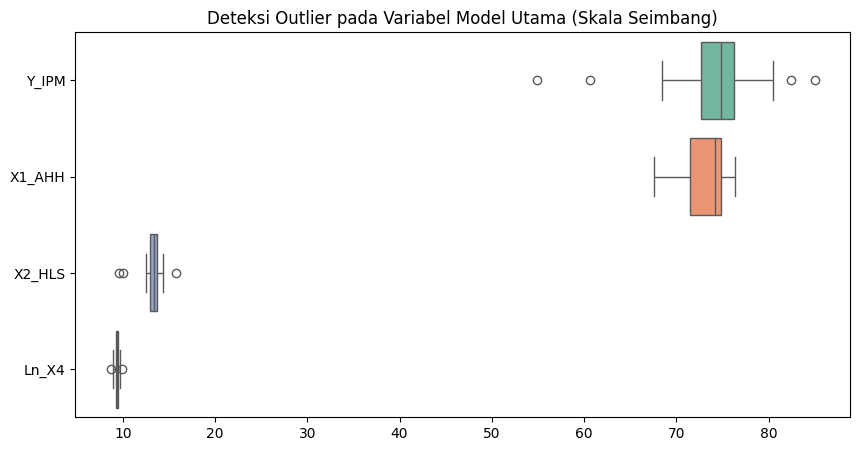

Menampilkan Scatter Plot Matrix untuk cek linearitas awal...


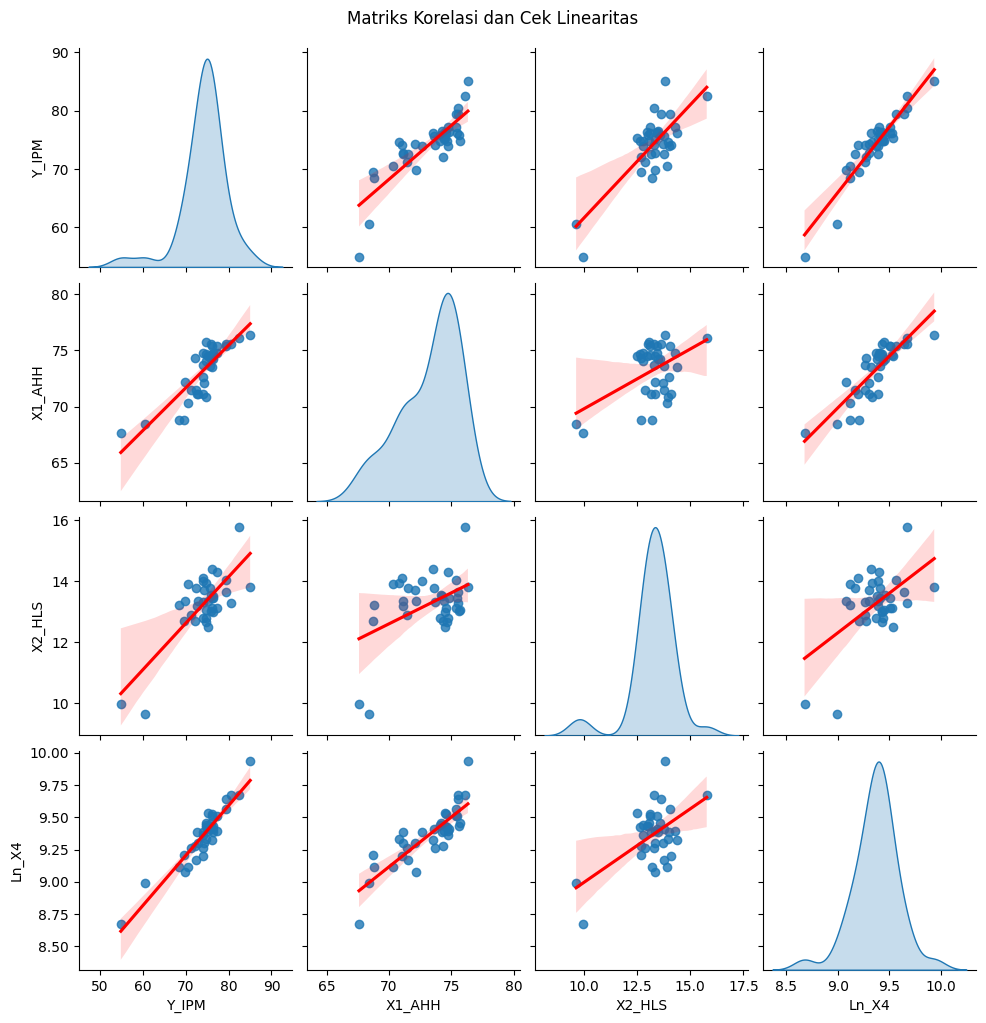

In [5]:
# 2. EKSPLORASI DATA (STATISTIK, OUTLIER, LINEARITAS)
print("="*70)
print(" "*25 + "STATISTIK DESKRIPTIF")
print("="*70)
print(df_merged[cols_to_numeric].describe().T[['mean', 'min', 'max', 'std']].round(3))
print("\n")

cols_for_plot = ['Y_IPM', 'X1_AHH', 'X2_HLS', 'Ln_X4']

# A. Visualisasi Outlier (Boxplot)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_merged[cols_for_plot], orient="h", palette="Set2")
plt.title("Deteksi Outlier pada Variabel Model Utama (Skala Seimbang)")
plt.show()

# B. Visualisasi Linearitas (Scatter Plot Matrix / Pairplot)
print("Menampilkan Scatter Plot Matrix untuk cek linearitas awal...")
sns.pairplot(df_merged[cols_for_plot], kind='reg', diag_kind='kde', plot_kws={'line_kws':{'color':'red'}})
plt.suptitle("Matriks Korelasi dan Cek Linearitas", y=1.02)
plt.show()

### 3. Pemodelan Regresi OLS Teroptimasi (Robust HAC)

Pada tahapan pemodelan ini, kita membangun persamaan regresi linear berganda menggunakan pustaka `statsmodels`. Terdapat beberapa perlakuan khusus dan penyesuaian metodologi ekonometrika lanjutan yang diterapkan pada blok kode ini untuk memastikan model akhir bersifat *robust* (tahan banting) dan valid secara statistik:

**A. Eliminasi Variabel Redundan**
Variabel Harapan Lama Sekolah (`X2_HLS`) dan Rata-rata Lama Sekolah (`X3_RLS`) pada dasarnya mengukur dimensi yang sama, yaitu sektor pendidikan. Memasukkan keduanya secara bersamaan ke dalam satu model memicu **Multikolinearitas Ekstrem**. Oleh karena itu, kita membuang `X3_RLS` dan hanya mempertahankan `X1_AHH`, `X2_HLS`, serta `Ln_X4` (variabel pengeluaran yang telah ditransformasi).

**B. Penambahan Konstanta (*Intercept*)**
Berbeda dengan aplikasi seperti SPSS, pustaka `statsmodels` di Python tidak menyertakan nilai konstanta ($B_0$) secara otomatis. Kita wajib menambahkannya melalui perintah `sm.add_constant(X)`. Tanpa fungsi ini, garis regresi akan dipaksa bermula dari titik koordinat nol (0,0), yang mana sangat tidak logis untuk data IPM.

**C. Penerapan Estimator Robust HAC / Newey-West**
>  **Catatan Ekonometrika:** Karena dataset ini adalah data *cross-section* wilayah (38 provinsi), data sangat rentan mengalami gangguan **Autokorelasi Spasial** (daerah yang berdekatan secara geografis cenderung saling mempengaruhi dan memiliki karakteristik serupa).

Untuk mencegah bias signifikansi akibat hal tersebut, fungsi `.fit()` kita modifikasi dengan parameter `cov_type='HAC', cov_kwds={'maxlags': 1}`. Metode *Heteroskedasticity and Autocorrelation Consistent* (HAC) atau Newey-West ini secara otomatis mengoreksi nilai *Standard Error* agar *p-value* yang dihasilkan menjadi **kebal terhadap gangguan autokorelasi maupun heteroskedastisitas**, sehingga kesimpulan Uji T dan Uji F dijamin valid.

**D. Ekstraksi Residual dan Prediksi**
Setelah model berhasil dibangun, langkah terakhir adalah mengekstrak atribut penting:
*   `residuals`: Merupakan nilai *error* (selisih antara tebakan model dengan data IPM yang asli).
*   `fitted_values`: Merupakan nilai IPM hasil prediksi murni dari model.
Keduanya disimpan sebagai variabel karena menjadi bahan baku utama untuk pengujian Asumsi Klasik di tahap selanjutnya.

In [6]:
# 3. PEMODELAN REGRESI OLS
# Membuang X3_RLS dan mempertahankan X2_HLS
X = df_merged[['X1_AHH', 'X2_HLS', 'Ln_X4']]
Y = df_merged['Y_IPM']
X_const = sm.add_constant(X) # Menambahkan Konstanta

# Model OLS Robust HAC / Newey-West
model_robust = sm.OLS(Y, X_const).fit(cov_type='HAC', cov_kwds={'maxlags': 1})
residuals = model_robust.resid
fitted_values = model_robust.fittedvalues

                          UJI ASUMSI KLASIK
1. Uji Normalitas (Shapiro-Wilk):
   P-Value = 0.3480
   -> KESIMPULAN: Residual berdistribusi NORMAL (Terpenuhi).

2. Uji Multikolinearitas (VIF):
   - X1_AHH   : VIF = 3.41 (Terpenuhi)
   - X2_HLS   : VIF = 1.42 (Terpenuhi)
   - Ln_X4    : VIF = 3.80 (Terpenuhi)

3. Uji Heteroskedastisitas (Breusch-Pagan):
   P-Value = 0.5280
   -> KESIMPULAN: Varians konstan / Homoskedastisitas (Terpenuhi).


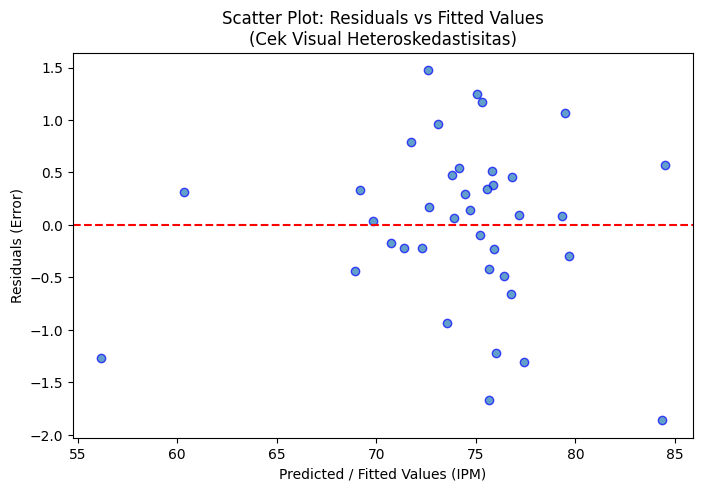


4. Uji Autokorelasi (Durbin-Watson):
   DW Stat = 1.4097
   -> KESIMPULAN: Terdapat gejala autokorelasi.
   *Catatan Teori: Data ini bersifat Cross-Section antar provinsi,
    sehingga uji autokorelasi secara teoritis tidak wajib dilakukan,
    kecuali jika menguji korelasi spasial antar daerah berdekatan.
    Gejala autokorelasi spasial telah dinetralisir oleh HAC Robust.




In [7]:
# 4. UJI ASUMSI KLASIK
print("="*70)
print(" "*26 + "UJI ASUMSI KLASIK")
print("="*70)

# A. Uji Normalitas (Shapiro-Wilk)
stat, p_value_norm = stats.shapiro(residuals)
print(f"1. Uji Normalitas (Shapiro-Wilk):")
print(f"   P-Value = {p_value_norm:.4f}")
if p_value_norm > 0.05:
    print("   -> KESIMPULAN: Residual berdistribusi NORMAL (Terpenuhi).")
else:
    print("   -> KESIMPULAN: Residual TIDAK normal (Tidak Terpenuhi).")

# B. Uji Multikolinearitas (VIF)
print("\n2. Uji Multikolinearitas (VIF):")
vif_data = pd.DataFrame()
vif_data["Variabel"] = X_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
for idx, row in vif_data.iloc[1:].iterrows():
    status = "Terpenuhi" if row['VIF'] < 10 else "TIDAK Terpenuhi (Kolinearitas Tinggi)"
    print(f"   - {row['Variabel']:<8} : VIF = {row['VIF']:.2f} ({status})")

# C. Uji Heteroskedastisitas (Breusch-Pagan Test)
print("\n3. Uji Heteroskedastisitas (Breusch-Pagan):")
bp_test = het_breuschpagan(residuals, X_const)
print(f"   P-Value = {bp_test[1]:.4f}")
if bp_test[1] > 0.05:
    print("   -> KESIMPULAN: Varians konstan / Homoskedastisitas (Terpenuhi).")
else:
    print("   -> KESIMPULAN: Terdapat gejala Heteroskedastisitas (Tidak Terpenuhi).")

# Visualisasi Scatter Plot Residual vs Fitted (Bukti Visual Heteroskedastisitas)
plt.figure(figsize=(8, 5))
plt.scatter(fitted_values, residuals, alpha=0.7, edgecolors='b')
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted / Fitted Values (IPM)")
plt.ylabel("Residuals (Error)")
plt.title("Scatter Plot: Residuals vs Fitted Values\n(Cek Visual Heteroskedastisitas)")
plt.show()

# D. Uji Autokorelasi (Durbin-Watson)
dw_stat = durbin_watson(residuals)
print(f"\n4. Uji Autokorelasi (Durbin-Watson):")
print(f"   DW Stat = {dw_stat:.4f}")
if 1.5 < dw_stat < 2.5:
     print("   -> KESIMPULAN: Tidak ada autokorelasi (Terpenuhi).")
else:
     print("   -> KESIMPULAN: Terdapat gejala autokorelasi.")
print("   *Catatan Teori: Data ini bersifat Cross-Section antar provinsi,")
print("    sehingga uji autokorelasi secara teoritis tidak wajib dilakukan,")
print("    kecuali jika menguji korelasi spasial antar daerah berdekatan.")
print("    Gejala autokorelasi spasial telah dinetralisir oleh HAC Robust.")
print("\n")

In [8]:
# 5. UJI HIPOTESIS & KELAYAKAN MODEL
print("="*70)
print(" "*13 + "HASIL REGRESI LINEAR BERGANDA (OLS SUMMARY)")
print("="*70)
# PERBAIKAN: Memanggil model_robust.summary()
print(model_robust.summary())

             HASIL REGRESI LINEAR BERGANDA (OLS SUMMARY)
                            OLS Regression Results                            
Dep. Variable:                  Y_IPM   R-squared:                       0.977
Model:                            OLS   Adj. R-squared:                  0.975
Method:                 Least Squares   F-statistic:                     307.8
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           1.06e-24
Time:                        13:18:41   Log-Likelihood:                -44.386
No. Observations:                  38   AIC:                             96.77
Df Residuals:                      34   BIC:                             103.3
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------

In [9]:
# 6. EVALUASI TANDA KOEFISIEN (Logika Ekonomi/Teori)
print("\n" + "="*70)
print(" "*10 + "EVALUASI LOGIKA TANDA KOEFISIEN (THEORETICAL CHECK)")
print("="*70)
# PERBAIKAN: Mengganti variabel menjadi list variabel yang benar-benar dipakai di model_robust
for var in ['X1_AHH', 'X2_HLS', 'Ln_X4']:
    coef = model_robust.params[var] # PERBAIKAN: model diubah menjadi model_robust
    arah = "Positif" if coef > 0 else "Negatif"
    print(f"- {var}: Tanda {arah} (Koefisien: {coef:.4f}).")
    if coef > 0:
        print(f"  Logika: Sesuai. Peningkatan {var} terbukti meningkatkan IPM.")
    else:
        print(f"  Logika: ANOMALI. Peningkatan {var} justru menurunkan IPM. Cek Multikolinearitas!")


          EVALUASI LOGIKA TANDA KOEFISIEN (THEORETICAL CHECK)
- X1_AHH: Tanda Positif (Koefisien: 0.3796).
  Logika: Sesuai. Peningkatan X1_AHH terbukti meningkatkan IPM.
- X2_HLS: Tanda Positif (Koefisien: 1.8677).
  Logika: Sesuai. Peningkatan X2_HLS terbukti meningkatkan IPM.
- Ln_X4: Tanda Positif (Koefisien: 14.1593).
  Logika: Sesuai. Peningkatan Ln_X4 terbukti meningkatkan IPM.



          K-MEANS CLUSTERING (4 KUADRAN KEBIJAKAN APBD)

Distribusi Provinsi Berdasarkan Kuadran Kebijakan:
                 Provinsi                     Rekomendasi_Kebijakan
                GORONTALO    Kuadran 1: Zona Merah (Evaluasi Total)
         SULAWESI SELATAN    Kuadran 1: Zona Merah (Evaluasi Total)
      NUSA TENGGARA BARAT    Kuadran 1: Zona Merah (Evaluasi Total)
                    JAMBI    Kuadran 1: Zona Merah (Evaluasi Total)
                     BALI    Kuadran 1: Zona Merah (Evaluasi Total)
                 BENGKULU    Kuadran 1: Zona Merah (Evaluasi Total)
               JAWA TIMUR    Kuadran 1: Zona Merah (Evaluasi Total)
KEPULAUAN BANGKA BELITUNG    Kuadran 1: Zona Merah (Evaluasi Total)
            DI YOGYAKARTA    Kuadran 1: Zona Merah (Evaluasi Total)
              JAWA TENGAH    Kuadran 1: Zona Merah (Evaluasi Total)
       KALIMANTAN SELATAN    Kuadran 1: Zona Merah (Evaluasi Total)
         KALIMANTAN BARAT             Kuadran 2: Zona Suntikan Dana
       

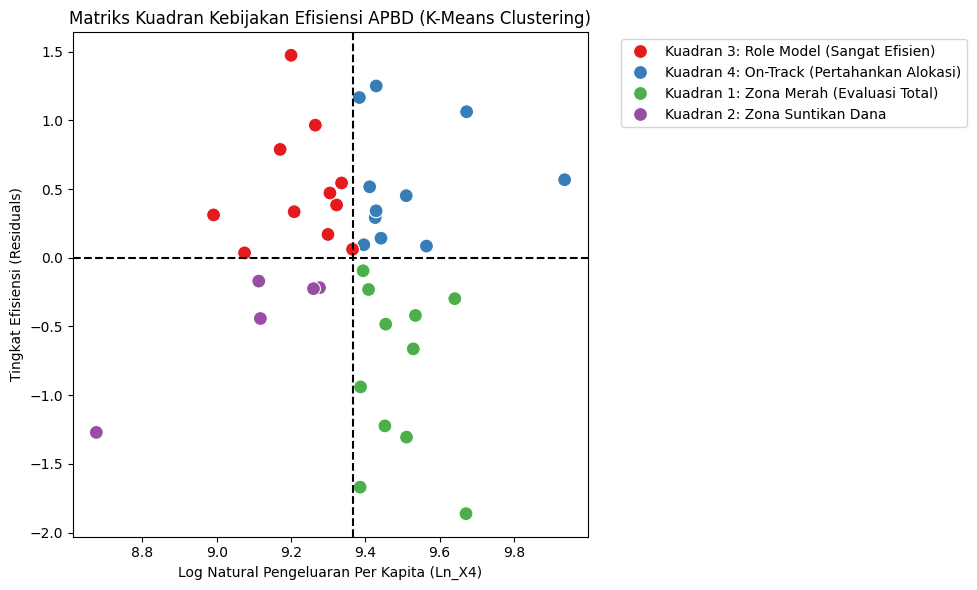

In [10]:
# ==============================================================================
# 7. ANALISIS K-MEANS CLUSTERING (4 KUADRAN KEBIJAKAN EFISIENSI APBD)
# ==============================================================================
print("\n" + "="*70)
print(" "*10 + "K-MEANS CLUSTERING (4 KUADRAN KEBIJAKAN APBD)")
print("="*70)

# A. Menyiapkan DataFrame Khusus K-Means
df_kmeans = pd.DataFrame({
    'Provinsi': df_merged['Provinsi'],
    'Ln_X4': df_merged['Ln_X4'],  # Representasi Anggaran
    'Residuals': residuals        # Representasi Efisiensi
})

# B. Standarisasi Data (Z-Score)
# WAJIB dilakukan karena rentang Ln_X4 (sekitar 9-10) jauh lebih besar dari Residuals (sekitar 0)
scaler = StandardScaler()
kmeans_scaled = scaler.fit_transform(df_kmeans[['Ln_X4', 'Residuals']])

# C. Eksekusi K-Means dengan K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_kmeans['Cluster'] = kmeans.fit_predict(kmeans_scaled)

# D. Penamaan Kuadran (Actionable Decision) berdasarkan Nilai Tengah
mean_ln_x4 = df_kmeans['Ln_X4'].mean()

def label_quadrant(row):
    if row['Ln_X4'] >= mean_ln_x4 and row['Residuals'] < 0:
        return "Kuadran 1: Zona Merah (Evaluasi Total)"
    elif row['Ln_X4'] < mean_ln_x4 and row['Residuals'] < 0:
        return "Kuadran 2: Zona Suntikan Dana"
    elif row['Ln_X4'] < mean_ln_x4 and row['Residuals'] >= 0:
        return "Kuadran 3: Role Model (Sangat Efisien)"
    else:
        return "Kuadran 4: On-Track (Pertahankan Alokasi)"

df_kmeans['Rekomendasi_Kebijakan'] = df_kmeans.apply(label_quadrant, axis=1)

# E. Menampilkan Tabel Keputusan untuk Slide PPT
print("\nDistribusi Provinsi Berdasarkan Kuadran Kebijakan:")
print(df_kmeans[['Provinsi', 'Rekomendasi_Kebijakan']].sort_values(by='Rekomendasi_Kebijakan').to_string(index=False))

# F. Visualisasi Scatter Plot untuk Slide 10 Pitch Deck
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_kmeans, x='Ln_X4', y='Residuals', hue='Rekomendasi_Kebijakan', palette='Set1', s=100)
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5) # Garis batas Efisiensi
plt.axvline(x=mean_ln_x4, color='black', linestyle='--', linewidth=1.5) # Garis batas Anggaran
plt.title("Matriks Kuadran Kebijakan Efisiensi APBD (K-Means Clustering)")
plt.xlabel("Log Natural Pengeluaran Per Kapita (Ln_X4)")
plt.ylabel("Tingkat Efisiensi (Residuals)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()